# Phase 4: exploring NECC egg prices

Four questions for the app's 7 zones, using NECC suggested prices (₹ per 100 eggs) since January 2009:

1. Which months are usually expensive, and does that hold across years?
2. How often, and by how much, do prices change?
3. How often does the price move ₹5 or less over 14 days? That is how often a ₹10 range around today's price would be right.
4. Which zones move first?

The last code cell writes `EggPaisa/Resources/necc_month_pattern.json` for the app's high-price months screen; the monthly job (`Pipeline/patterns.py`) does the same with `high_months.py`. A day without a NECC price uses the previous day's price. Run `python3 Scripts/necc.py update` first to include the latest prices.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import high_months

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "Data" / "necc_daily.csv").exists())
APP_PRICES = json.loads((ROOT / "EggPaisa" / "Resources" / "necc_prices.json").read_text(encoding="utf-8"))
ZONES = {zone["neccName"]: zone["name"] for zone in APP_PRICES["zones"]}  # NECC name -> app name, in app order
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

rows = pd.read_csv(ROOT / "Data" / "necc_daily.csv", parse_dates=["date"])
published = rows.pivot(index="date", columns="zone", values="price")
calendar_days = pd.date_range(published.index.min(), published.index.max(), freq="D")
# A missing day takes the previous day's price; nothing is filled before a zone's first or after its latest price.
daily = published.reindex(calendar_days).ffill(limit_area="inside")
LAST_DAY = daily.index.max()
prices = daily[list(ZONES)].rename(columns=ZONES)

pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 96, "axes.grid": True, "grid.alpha": 0.3})
filled = published[list(ZONES)].reindex(calendar_days).isna().sum().rename(ZONES)
print(f"{len(rows):,} NECC prices for {published.shape[1]} zones, {calendar_days[0]:%d %b %Y} to {LAST_DAY:%d %b %Y}")
print("Days filled from the previous day:", filled.to_dict())

201,925 NECC prices for 37 zones, 01 Jan 2009 to 27 Oct 2026
Days filled from the previous day: {'Chittoor': 2, 'Chennai': 3, 'Bengaluru': 2, 'Namakkal': 3, 'Kolkata': 16, 'Vijayawada': 2, 'Hyderabad': 5}


## Prices over time

Monthly averages; the current month is left out until it is complete. Prices rise year after year, so the seasonal pattern below is measured against a moving yearly average rather than a fixed price.

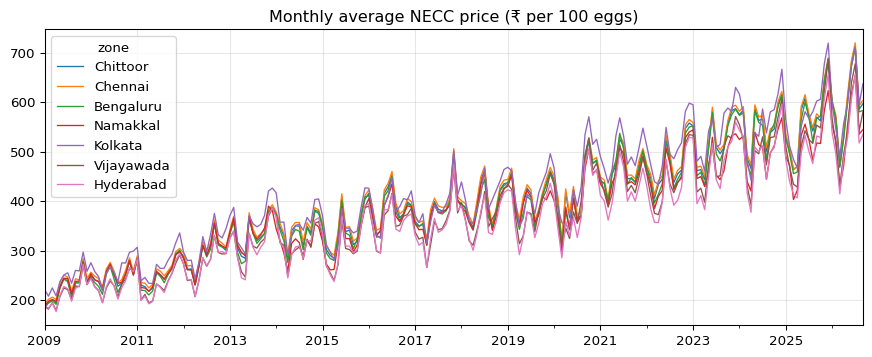

,2009 average (₹),2025 average (₹),rise per year (%)
zone,,,
Chittoor,223.3,560.6,5.9
Chennai,230.2,566.3,5.8
Bengaluru,222.2,555.7,5.9
Namakkal,225.0,510.8,5.3
Kolkata,242.9,576.6,5.6
Vijayawada,212.9,529.2,5.9
Hyderabad,213.2,506.8,5.6


In [ ]:
monthly = high_months.complete_months(prices)  # the current month counts only once it is complete

ax = monthly.plot(figsize=(11, 4), lw=1, title="Monthly average NECC price (₹ per 100 eggs)")
ax.set_xlabel("")
plt.show()

full_years = prices[prices.index.year < LAST_DAY.year]
yearly = full_years.groupby(full_years.index.year).mean()
first, last = yearly.index[0], yearly.index[-1]
pd.DataFrame({
    f"{first} average (₹)": yearly.loc[first],
    f"{last} average (₹)": yearly.loc[last],
    "rise per year (%)": ((yearly.loc[last] / yearly.loc[first]) ** (1 / (last - first)) - 1) * 100,
}).round(1)

## 1. High-price months

Each month's average is divided by the centred 12-month average around it, which takes out the long-term rise. For each calendar month:

- **bar**: the median across years, so one-off shocks such as the 2020 COVID rumours don't dominate
- **line**: the middle half of years (25th to 75th percentile)
- **years above**: in how many years the month was above its yearly average

The 12 medians are scaled so they average 0%. These are the numbers the app shows.

In [ ]:
ratio = high_months.ratio_to_trend(monthly)  # each month ÷ the centred 12-month average around it
patterns = {zone: high_months.month_pattern(ratio[zone]) for zone in prices.columns}
compared = ratio.dropna(how="all").index
print(f"Months compared: {compared[0]:%b %Y} to {compared[-1]:%b %Y}")
(
    pd.DataFrame({zone: pattern["percent"] for zone, pattern in patterns.items()}).T
    .set_axis(MONTHS, axis=1)
    .style.format("{:+.0f}%")
    .background_gradient(cmap="RdYlGn", vmin=-20, vmax=20, axis=None)
)

Months compared: Jul 2009 to Mar 2026


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Chittoor,+5%,-4%,-10%,-13%,-1%,+9%,+1%,-5%,-3%,+1%,+10%,+9%
Chennai,+4%,-4%,-10%,-12%,-1%,+9%,+1%,-5%,-3%,+1%,+10%,+8%
Bengaluru,+6%,-3%,-9%,-14%,-2%,+9%,+1%,-7%,-3%,+1%,+11%,+10%
Namakkal,+4%,-4%,-10%,-12%,-1%,+9%,+1%,-7%,-1%,+1%,+11%,+10%
Kolkata,+8%,-4%,-10%,-16%,-6%,+2%,-2%,-4%,+1%,+4%,+12%,+14%
Vijayawada,+9%,-5%,-12%,-16%,-7%,+4%,-1%,-6%,+1%,+3%,+13%,+16%
Hyderabad,+9%,-5%,-11%,-17%,-6%,+6%,-1%,-8%,-1%,+4%,+15%,+16%


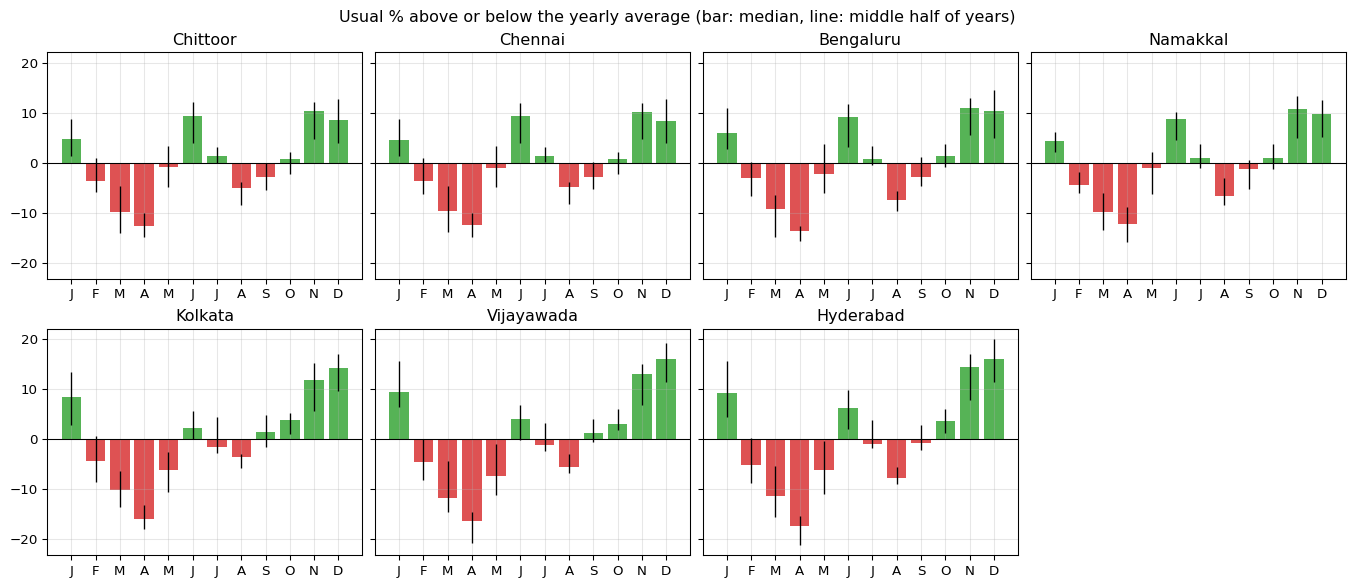

In [4]:
positions = np.arange(12)
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey=True, constrained_layout=True)
for ax, (zone, pattern) in zip(axes.flat, patterns.items()):
    colors = np.where(pattern["percent"] >= 0, "tab:green", "tab:red")
    ax.bar(positions, pattern["percent"], color=colors, alpha=0.8)
    ax.vlines(positions, pattern["low"], pattern["high"], color="black", lw=1)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(positions, [month[0] for month in MONTHS])
    ax.set_title(zone)
axes[-1, -1].axis("off")
fig.suptitle("Usual % above or below the yearly average (bar: median, line: middle half of years)")
plt.show()

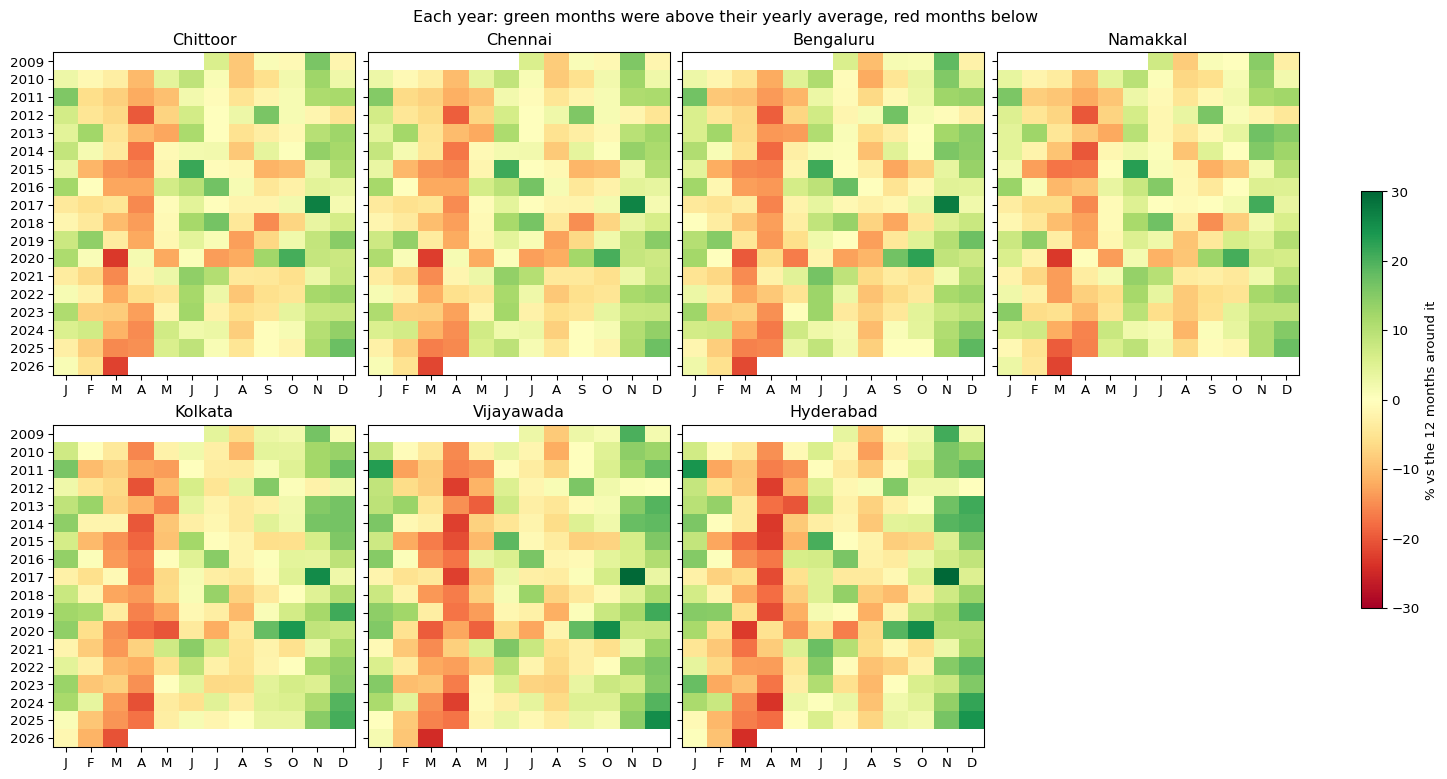

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8), sharey=True, constrained_layout=True)
for ax, zone in zip(axes.flat, prices.columns):
    values = (ratio[zone].dropna() - 1) * 100
    grid = pd.DataFrame({"year": values.index.year, "month": values.index.month, "percent": values.to_numpy()})
    grid = grid.pivot(index="year", columns="month", values="percent")
    image = ax.imshow(grid, cmap="RdYlGn", vmin=-30, vmax=30, aspect="auto")
    ax.set_xticks(range(12), [month[0] for month in MONTHS])
    ax.set_yticks(range(len(grid)), grid.index)
    ax.set_title(zone)
    ax.grid(False)
axes[-1, -1].axis("off")
fig.colorbar(image, ax=axes, shrink=0.6, label="% vs the 12 months around it")
fig.suptitle("Each year: green months were above their yearly average, red months below")
plt.show()

In [6]:
def ranked(pattern: pd.DataFrame, highest: bool) -> str:
    """Top or bottom three months, with the years each was above (or below) its yearly average."""
    texts = []
    for month in pattern["percent"].sort_values(ascending=not highest).index[:3]:
        row = pattern.loc[month]
        years = row.years_above if highest else row.years - row.years_above
        texts.append(f"{MONTHS[month - 1]} {row.percent:+.0f}% ({years:.0f} of {row.years:.0f} years)")
    return ", ".join(texts)


pd.DataFrame({
    "usually highest": {zone: ranked(pattern, highest=True) for zone, pattern in patterns.items()},
    "usually lowest": {zone: ranked(pattern, highest=False) for zone, pattern in patterns.items()},
})

,usually highest,usually lowest
Chittoor,"Nov +10% (16 of 17 years), Jun +9% (16 of 16 y...","Apr -13% (15 of 16 years), Mar -10% (17 of 17 ..."
Chennai,"Nov +10% (16 of 17 years), Jun +9% (16 of 16 y...","Apr -12% (15 of 16 years), Mar -10% (17 of 17 ..."
Bengaluru,"Nov +11% (16 of 17 years), Dec +10% (15 of 17 ...","Apr -14% (16 of 16 years), Mar -9% (17 of 17 y..."
Namakkal,"Nov +11% (16 of 17 years), Dec +10% (15 of 17 ...","Apr -12% (16 of 16 years), Mar -10% (17 of 17 ..."
Kolkata,"Dec +14% (17 of 17 years), Nov +12% (16 of 17 ...","Apr -16% (16 of 16 years), Mar -10% (17 of 17 ..."
Vijayawada,"Dec +16% (17 of 17 years), Nov +13% (17 of 17 ...","Apr -16% (16 of 16 years), Mar -12% (17 of 17 ..."
Hyderabad,"Dec +16% (17 of 17 years), Nov +15% (17 of 17 ...","Apr -17% (16 of 16 years), Mar -11% (17 of 17 ..."


## 2. How often and how much prices change

A change is a day whose price differs from the day before. "Last 3 years" shows how NECC sets prices now.

In [7]:
RECENT = LAST_DAY - pd.DateOffset(years=3)
changes = prices.diff()


def change_stats(window: pd.DataFrame) -> pd.DataFrame:
    moved = window.ne(0) & window.notna()
    sizes = window.abs().where(moved)
    return pd.DataFrame({
        "days with a change (%)": moved.sum() / window.notna().sum() * 100,
        "changes per month": moved.sum() / window.notna().sum() * 30.44,
        "median change (₹)": sizes.median(),
        "multiple of ₹5 (%)": (sizes % 5 == 0).sum() / moved.sum() * 100,
        "largest rise (₹)": window.max(),
        "largest fall (₹)": window.min(),
    })


for title, window in [("All years", changes), ("Last 3 years", changes[changes.index > RECENT])]:
    print(title)
    display(change_stats(window).round(1))

All years


,days with a change (%),changes per month,median change (₹),multiple of ₹5 (%),largest rise (₹),largest fall (₹)
zone,,,,,,
Chittoor,23.2,7.0,10.0,84.7,75.0,-50.0
Chennai,23.2,7.0,10.0,85.3,75.0,-50.0
Bengaluru,33.1,10.1,5.0,80.5,60.0,-60.0
Namakkal,27.4,8.3,7.0,76.4,60.0,-80.0
Kolkata,51.0,15.5,5.0,52.5,110.0,-140.0
Vijayawada,46.2,14.1,5.0,39.3,65.0,-70.0
Hyderabad,49.1,14.9,5.0,47.1,65.0,-60.0


Last 3 years


,days with a change (%),changes per month,median change (₹),multiple of ₹5 (%),largest rise (₹),largest fall (₹)
zone,,,,,,
Chittoor,24.5,7.4,10.0,99.3,70.0,-35.0
Chennai,24.5,7.4,10.0,100.0,70.0,-35.0
Bengaluru,33.6,10.2,5.0,99.5,60.0,-30.0
Namakkal,30.5,9.3,5.0,100.0,60.0,-40.0
Kolkata,50.5,15.4,10.0,92.6,45.0,-55.0
Vijayawada,40.9,12.4,10.0,91.7,55.0,-55.0
Hyderabad,46.0,14.0,5.0,93.8,55.0,-50.0


Size of each change, last 3 years (% of changes)


,under ₹5,₹5,₹6–10,₹11–15,over ₹15
zone,,,,,
Chittoor,0.0,8.0,48.0,9.0,35.0
Chennai,0.0,8.0,48.0,9.0,36.0
Bengaluru,0.0,53.0,21.0,3.0,23.0
Namakkal,0.0,54.0,20.0,1.0,24.0
Kolkata,3.0,30.0,31.0,13.0,23.0
Vijayawada,5.0,33.0,28.0,10.0,23.0
Hyderabad,5.0,62.0,10.0,2.0,21.0


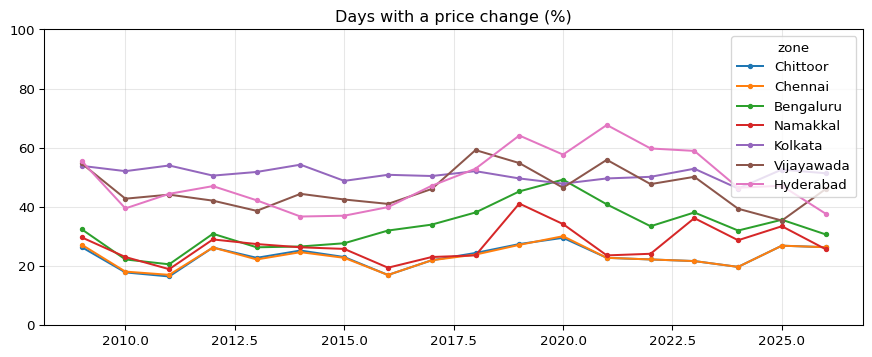

In [8]:
recent = changes[changes.index > RECENT]
sizes = recent.abs().where(recent.ne(0))
bins, labels = [0, 4.99, 5, 10, 15, np.inf], ["under ₹5", "₹5", "₹6–10", "₹11–15", "over ₹15"]
buckets = sizes.apply(lambda zone: pd.cut(zone.dropna(), bins, labels=labels).value_counts(normalize=True, sort=False))
print("Size of each change, last 3 years (% of changes)")
display((buckets.T * 100).round(0))

moved = changes.ne(0) & changes.notna()
by_year = moved.groupby(changes.index.year).sum() / changes.notna().groupby(changes.index.year).sum() * 100
ax = by_year.plot(figsize=(11, 4), marker="o", ms=3, title="Days with a price change (%)")
ax.set(xlabel="", ylim=(0, 100))
plt.show()

## 3. How often a ₹10 range around today's price would be right

For each day and each horizon from 1 to 14 days, is the later price within ₹5 of that day's price? A ₹10 range around today's price (545–555 when today is 550) is right in exactly these cases. This is the simplest range forecast, and the one Phase 7 has to beat.

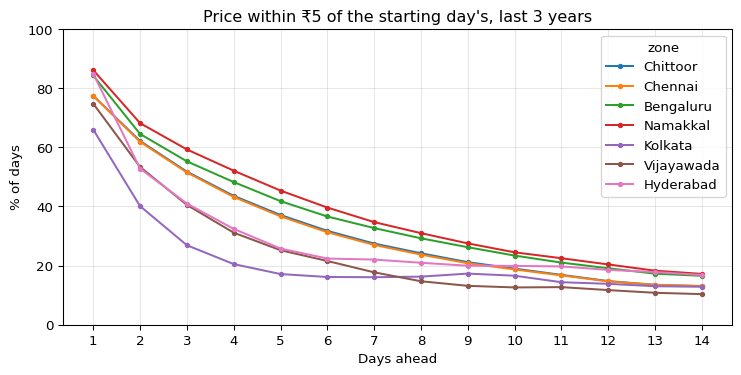

,"All years, 1 days ahead","All years, 7 days ahead","All years, 14 days ahead","Last 3 years, 1 days ahead","Last 3 years, 7 days ahead","Last 3 years, 14 days ahead"
zone,,,,,,
Chittoor,83.0,33.0,18.0,77.0,27.0,13.0
Chennai,83.0,33.0,18.0,77.0,27.0,13.0
Bengaluru,86.0,33.0,18.0,84.0,33.0,17.0
Namakkal,85.0,34.0,19.0,86.0,35.0,17.0
Kolkata,76.0,21.0,15.0,66.0,16.0,13.0
Vijayawada,83.0,26.0,16.0,75.0,18.0,10.0
Hyderabad,85.0,26.0,16.0,85.0,22.0,17.0


In [9]:
HORIZONS = range(1, 15)


def within_5(since: pd.Timestamp) -> pd.DataFrame:
    """% of starting days after `since` whose price h days later is within ₹5; one row per h."""
    rates = {}
    for days in HORIZONS:
        moves = (prices.shift(-days) - prices).abs()
        moves = moves[moves.index > since]
        rates[days] = (moves <= 5).sum() / moves.notna().sum() * 100
    return pd.DataFrame(rates).T


all_years = within_5(prices.index[0] - pd.Timedelta(days=1))
last_3_years = within_5(RECENT)
ax = last_3_years.plot(figsize=(9, 4), marker="o", ms=3, title="Price within ₹5 of the starting day's, last 3 years")
ax.set(xlabel="Days ahead", ylabel="% of days", ylim=(0, 100), xticks=list(HORIZONS))
plt.show()

summary = pd.concat({"All years": all_years.loc[[1, 7, 14]].T, "Last 3 years": last_3_years.loc[[1, 7, 14]].T}, axis=1)
summary.columns = [f"{period}, {days} days ahead" for period, days in summary.columns]
summary.round(0)

In [10]:
LAST_5_YEARS = LAST_DAY - pd.DateOffset(years=5)
moves_14 = (prices.shift(-14) - prices).abs()
moves_14 = moves_14[moves_14.index > LAST_5_YEARS]
hits = (moves_14 <= 5).astype(float).where(moves_14.notna())
print("14 days ahead within ₹5, by starting month, last 5 years (% of days)")
(
    (hits.groupby(hits.index.month).mean() * 100).T
    .set_axis(MONTHS, axis=1)
    .style.format("{:.0f}")
    .background_gradient(cmap="Blues", vmin=0, vmax=40, axis=None)
)

14 days ahead within ₹5, by starting month, last 5 years (% of days)


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
zone,,,,,,,,,,,,
Chittoor,10,18,16,4,8,17,8,11,23,1,17,17
Chennai,10,18,17,4,8,17,8,11,23,1,17,17
Bengaluru,17,13,17,7,10,22,6,15,32,13,23,8
Namakkal,12,19,19,12,12,22,11,12,31,9,23,6
Kolkata,12,9,14,7,14,7,6,11,16,12,20,14
Vijayawada,14,9,12,9,8,6,5,11,23,13,15,16
Hyderabad,20,19,12,11,12,5,8,21,32,23,11,14


## 4. Which zones move first

Correlation between one zone's daily price change and another zone's change k days later, over the last 5 years. A peak at k = 1 means the first zone usually moves a day earlier, 0 means both move on the same day, and −1 means the second zone moves first. E.Godavari, Warangal and Barwala (a North Indian hub) are included for reference.

In [11]:
moves = daily.loc[daily.index > LAST_5_YEARS].diff().rename(columns=ZONES)
LAGS = list(range(-3, 4))
PAIRS = [
    ("Namakkal", "Chennai"), ("Namakkal", "Chittoor"), ("Namakkal", "Bengaluru"),
    ("Hyderabad", "Bengaluru"), ("Hyderabad", "Chennai"), ("Hyderabad", "Warangal"),
    ("E.Godavari", "Vijayawada"), ("Vijayawada", "Hyderabad"),
    ("Vijayawada", "Kolkata"), ("E.Godavari", "Kolkata"), ("Barwala", "Kolkata"),
]
lead_lag = pd.DataFrame({
    f"{leader} → {follower}": {lag: moves[leader].shift(lag).corr(moves[follower]) for lag in LAGS}
    for leader, follower in PAIRS
}).T
lead_lag["peak (days)"] = lead_lag[LAGS].idxmax(axis=1)
lead_lag.style.format("{:.2f}", subset=LAGS).background_gradient(cmap="Blues", subset=LAGS, axis=1)

,-3,-2,-1,0,1,2,3,peak (days)
Namakkal → Chennai,0.11,0.21,0.31,0.50,0.56,0.26,0.20,1
Namakkal → Chittoor,0.11,0.21,0.31,0.50,0.57,0.26,0.20,1
Namakkal → Bengaluru,0.13,0.27,0.35,0.77,0.42,0.26,0.13,0
Hyderabad → Bengaluru,0.06,0.19,0.27,0.50,0.53,0.33,0.23,1
Hyderabad → Chennai,0.08,0.14,0.24,0.37,0.46,0.39,0.25,1
Hyderabad → Warangal,0.08,0.20,0.33,0.99,0.32,0.20,0.08,0
E.Godavari → Vijayawada,0.05,0.21,0.24,0.88,0.25,0.20,0.04,0
Vijayawada → Hyderabad,0.11,0.22,0.41,0.55,0.32,0.25,0.06,0
Vijayawada → Kolkata,0.12,0.26,0.52,0.40,0.21,0.10,-0.01,-1
E.Godavari → Kolkata,0.13,0.26,0.53,0.40,0.21,0.09,-0.02,-1


In [12]:
covered = moves.columns[moves.notna().mean() > 0.9]
kolkata = moves["Kolkata"]
follows = pd.DataFrame({
    "1 day earlier": moves[covered].shift(1).corrwith(kolkata),
    "same day": moves[covered].corrwith(kolkata),
    "1 day later": moves[covered].shift(-1).corrwith(kolkata),
}).drop(index="Kolkata")
print("Zones Kolkata follows: their change comes a day before Kolkata's (correlation)")
display(follows.sort_values("1 day earlier", ascending=False).head(6).round(2))
print("Zones that follow Kolkata: their change comes a day after Kolkata's")
display(follows.sort_values("1 day later", ascending=False).head(6).round(2))

Zones Kolkata follows: their change comes a day before Kolkata's (correlation)


,1 day earlier,same day,1 day later
zone,,,
Barwala,0.4,0.4,0.3
Patna,0.3,0.4,0.3
Muzaffurpur (CC),0.3,0.4,0.3
Ajmer,0.3,0.4,0.2
Varanasi (CC),0.3,0.4,0.3
Indore (CC),0.3,0.4,0.2


Zones that follow Kolkata: their change comes a day after Kolkata's


,1 day earlier,same day,1 day later
zone,,,
W.Godavari,0.2,0.4,0.5
E.Godavari,0.2,0.4,0.5
Vijayawada,0.2,0.4,0.5
Mumbai (CC),0.2,0.4,0.5
Brahmapur (OD),0.2,0.6,0.5
Pune,0.2,0.4,0.5


In [13]:
def gap_by_year(higher: str, lower: str) -> pd.DataFrame:
    gap = (daily[higher] - daily[lower]).dropna()
    by_year = gap.groupby(gap.index.year)
    return pd.DataFrame({
        "usual gap (₹)": by_year.agg(lambda year: year.mode().iloc[0]),
        "days at that gap (%)": by_year.apply(lambda year: (year == year.mode().iloc[0]).mean() * 100),
    })


pd.concat({
    "Chennai − Chittoor": gap_by_year("Chennai (CC)", "Chittoor"),
    "Warangal − Hyderabad": gap_by_year("Warangal", "Hyderabad"),
}, axis=1).T.round(0)

2009  2010  2011  2012  2013  2014  \
Chennai − Chittoor   usual gap (₹)          7.0   7.0   7.0   7.0   7.0   7.0   
                     days at that gap (%)  97.0  97.0  98.0  99.0  96.0  96.0   
Warangal − Hyderabad usual gap (₹)          1.0   2.0   4.0   4.0   4.0   4.0   
                     days at that gap (%)  97.0  50.0  77.0  87.0  84.0  87.0   

                                           2015   2016   2017  2018  2019  \
Chennai − Chittoor   usual gap (₹)          7.0    7.0    7.0   7.0   7.0   
                     days at that gap (%)  98.0  100.0  100.0  98.0  99.0   
Warangal − Hyderabad usual gap (₹)          4.0    3.0    2.0   2.0   3.0   
                     days at that gap (%)  78.0   55.0   44.0  47.0  30.0   

                                           2020   2021   2022   2023   2024  \
Chennai − Chittoor   usual gap (₹)          7.0    7.0    7.0    7.0    7.0   
                     days at that gap (%)  99.0  100.0  100.0  100.0  100.0   
Warangal − Hyderabad usual gap (₹)          3.0    2.0    2.0    2.0    2.0   
                     days at that gap (%)  40.0   98.0   93.0  100.0  100.0   

                                           2025   2026  
Chennai − Chittoor   usual gap (₹)          7.0    7.0  
                     days at that gap (%)  87.0  100.0  
Warangal − Hyderabad usual gap (₹)          2.0    2.0  
                     days at that gap (%)  99.0  100.0

## Month pattern for the app

Writes the month bars above, plus the festivals and seasons for each zone's screen from Phase 6: their current or next dates (and the ones after, so the app can move on) and what they did to prices in 2009–2026. North Indian festivals are listed only for zones where they clearly moved prices. The code is in `high_months.py`; the monthly job, `Pipeline/patterns.py`, runs it once a month of NECC prices is complete.

In [ ]:
payload = high_months.app_payload()
high_months.check(payload)
high_months.write_payload(payload)
PATTERN_PATH = high_months.PATTERN_PATH
print(f"Wrote {PATTERN_PATH.relative_to(ROOT)} ({PATTERN_PATH.stat().st_size / 1024:.1f} KB), "
      f"NECC months {payload['firstMonth']} to {payload['lastMonth']}")

Wrote EggPaisa/Resources/necc_month_pattern.json (36.1 KB), NECC months 2009-01 to 2026-09


## Findings (data to 26 Oct 2026)

- **High-price months:** November and December in every zone (+8% to +16%), above their yearly average in 15–17 of 17 years. The southern zones also have a June peak (+4% to +9%), and January stays high in Kolkata, Vijayawada and Hyderabad.
- **Low-price months:** March and April everywhere (−9% to −17%); April was below its yearly average in 15–16 of 16 years. August dips 5–8% in the southern zones, around Shravana.
- **Price changes:** Chittoor and Chennai change about 7 times a month, usually by ₹10. Bengaluru and Namakkal change 8–10 times, usually by ₹5. Kolkata, Hyderabad and Vijayawada change 12–15 times. In the last 3 years, 92–100% of changes were multiples of ₹5.
- **₹10 range:** a range around today's price would have been right 66–86% of the time 1 day ahead, 16–35% at 7 days and only 10–17% at 14 days. It does even worse when started in the months when prices move most. The forecast has to predict the direction, and the probability shown for later days will be low.
- **Who moves first:** Namakkal changes a day before Chennai and Chittoor, and on the same day as Bengaluru. Hyderabad tends to change a day before Bengaluru and Chennai. Kolkata changes a day before Vijayawada and the Godavari zones; it follows North Indian zones such as Barwala and Patna only weakly.
- **Fixed gaps:** Chittoor was Chennai − ₹7 on 96–100% of days every year except 2025 (87%). Warangal has been Hyderabad + ₹2 since 2021.